# 06 — Analyse PairDistill-lite (BM25 → BGE-small)

Distillation de connaissance~: le **teacher** BM25 supervise un **student** BGE-small-en-v1.5 (33M params).

L'objectif d'entraînement est pairwise : le student apprend à reproduire les **préférences relatives** du teacher plutôt que ses scores absolus.

Évaluation sur MS MARCO dev (subset 10% corpus, 884K passages).

## 1. Setup & chargement des données

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

RESULTS = Path('../results')
OUT_DIR = RESULTS / 'analysis' / '06_pairdistill'
OUT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {
    'rouge':      '#C8102E',
    'or':         '#F0A500',
    'bleu_nuit':  '#1A2D5A',
    'gris_fonce': '#4A4A4A',
    'gris_clair': '#D3D3D3',
}

def load(path):
    return json.loads(Path(path).read_text())

bm25       = load(RESULTS / 'baselines/bm25_msmarco_dev/metrics.json')
dense_large = load(RESULTS / 'dense/evaluation/dense_bge_large_subset30_msmarco_dev/metrics.json')
pd_metrics = load(RESULTS / 'pairdistill/evaluation/pairdistill_bge_small_subset10_msmarco_dev/metrics.json')
pd_train   = load(Path('../results/pairdistill/training/pairdistill_training.json'))

print('BM25         MRR@10 =', bm25['MRR@10'],    '| Recall@100 =', bm25['Recall@100'])
print('BGE-large ZS MRR@10 =', dense_large['MRR@10'], '| Recall@100 =', dense_large['Recall@100'])
print('PairDistill  MRR@10 =', pd_metrics['MRR@10'],  '| Recall@100 =', pd_metrics['Recall@100'])

BM25         MRR@10 = 0.1697 | Recall@100 = 0.6169
BGE-large ZS MRR@10 = 0.2574887054471582 | Recall@100 = 0.3828398599172238
PairDistill  MRR@10 = 0.26446486361534904 | Recall@100 = 0.561084142394822


## 2. Figure 1 — Courbes de perte d'entraînement (2 époques)

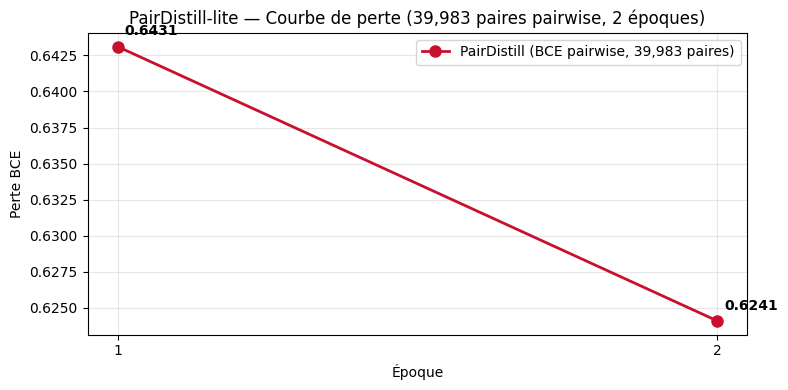

Figure sauvegardée.


In [2]:
history = pd_train['history']
epochs  = [h['epoch'] for h in history]
losses  = [h['loss']  for h in history]
n_pairs = history[0]['examples']

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epochs, losses, marker='o', markersize=8, color=COLORS['rouge'],
        linewidth=2, label=f'PairDistill (BCE pairwise, {n_pairs:,} paires)')
for e, l in zip(epochs, losses):
    ax.annotate(f'{l:.4f}', (e, l), textcoords='offset points',
                xytext=(5, 8), fontsize=10, fontweight='bold')

ax.set_xlabel('Époque')
ax.set_ylabel('Perte BCE')
ax.set_xticks(epochs)
ax.set_title(f'PairDistill-lite — Courbe de perte ({n_pairs:,} paires pairwise, 2 époques)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / 'pairdistill_training_loss.png', dpi=150)
plt.show()
print(f'Figure sauvegardée.')

## 3. Figure 2 — Comparaison Recall@k (BM25 / BGE-large ZS / PairDistill)

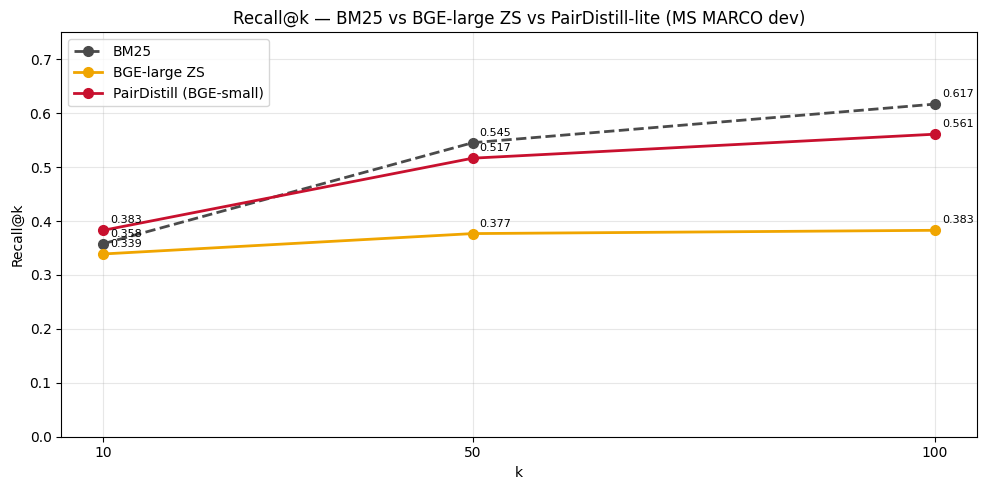

Figure sauvegardée.


In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

systems_data = [
    ('BM25',          bm25,        COLORS['gris_fonce'], '--'),
    ('BGE-large ZS',  dense_large, COLORS['or'],         '-'),
    ('PairDistill\n(BGE-small)',  pd_metrics,  COLORS['rouge'],    '-'),
]

k_vals = [10, 50, 100]

for label, m, color, ls in systems_data:
    recalls = []
    for k in k_vals:
        key = f'Recall@{k}'
        if key in m:
            recalls.append(m[key])
        else:
            recalls.append(None)
    # Filter out None values
    valid_k = [k for k, r in zip(k_vals, recalls) if r is not None]
    valid_r = [r for r in recalls if r is not None]
    ax.plot(valid_k, valid_r, marker='o', markersize=7, color=color,
            linestyle=ls, linewidth=2, label=label.replace('\n', ' '))
    for k, r in zip(valid_k, valid_r):
        ax.annotate(f'{r:.3f}', (k, r), textcoords='offset points',
                    xytext=(5, 5), fontsize=8)

ax.set_xlabel('k')
ax.set_ylabel('Recall@k')
ax.set_xticks(k_vals)
ax.set_ylim(0, 0.75)
ax.set_title('Recall@k — BM25 vs BGE-large ZS vs PairDistill-lite (MS MARCO dev)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / 'recall_at_k_comparison.png', dpi=150)
plt.show()
print(f'Figure sauvegardée.')

## 4. Figure 3 — Comparaison MRR@10 et nDCG@10

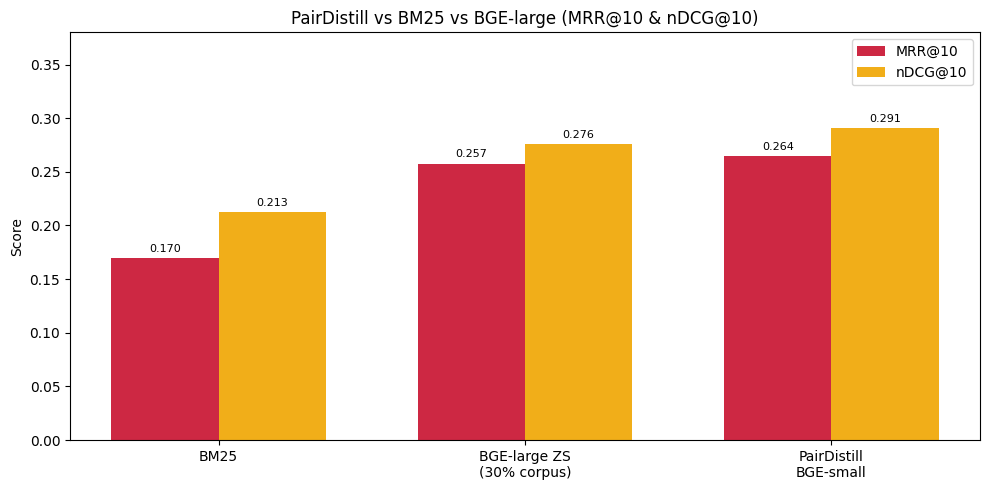

Figures sauvegardées dans ../results/analysis/06_pairdistill


In [4]:
systems = ['BM25', 'BGE-large ZS\n(30% corpus)', 'PairDistill\nBGE-small']
mrr   = [bm25['MRR@10'], dense_large['MRR@10'], pd_metrics['MRR@10']]
ndcg  = [bm25['nDCG@10'], dense_large['nDCG@10'], pd_metrics['nDCG@10']]

x = np.arange(len(systems))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, mrr,  width, label='MRR@10',  color=COLORS['rouge'], alpha=0.9)
bars2 = ax.bar(x + width/2, ndcg, width, label='nDCG@10', color=COLORS['or'],    alpha=0.9)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(systems)
ax.set_ylim(0, 0.38)
ax.set_ylabel('Score')
ax.set_title('PairDistill vs BM25 vs BGE-large (MRR@10 & nDCG@10)')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'pairdistill_mrr_ndcg.png', dpi=150)
plt.show()
print(f'Figures sauvegardées dans {OUT_DIR}')